<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2583 entries, 0 to 2582
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Date      2583 non-null   object
 1   Price     2583 non-null   object
 2   Open      2583 non-null   object
 3   High      2583 non-null   object
 4   Low       2583 non-null   object
 5   Vol.      2578 non-null   object
 6   Change %  2583 non-null   object
dtypes: object(7)
memory usage: 141.4+ KB
        Date   Price    Open    High     Low
0 2013-01-02  1689.9  1675.8  1695.0  1672.1
1 2013-01-03  1675.6  1688.0  1689.3  1664.3
2 2013-01-04  1649.9  1664.4  1664.4  1630.0
3 2013-01-07  1647.2  1657.3  1663.8  1645.3
4 2013-01-08  1663.2  1651.5  1662.6  1648.8
Duplicated rows: 0
Null values:
 Date     0
Price    0
Open     0
High     0
Low      0
dtype: int64


Test data count: 260


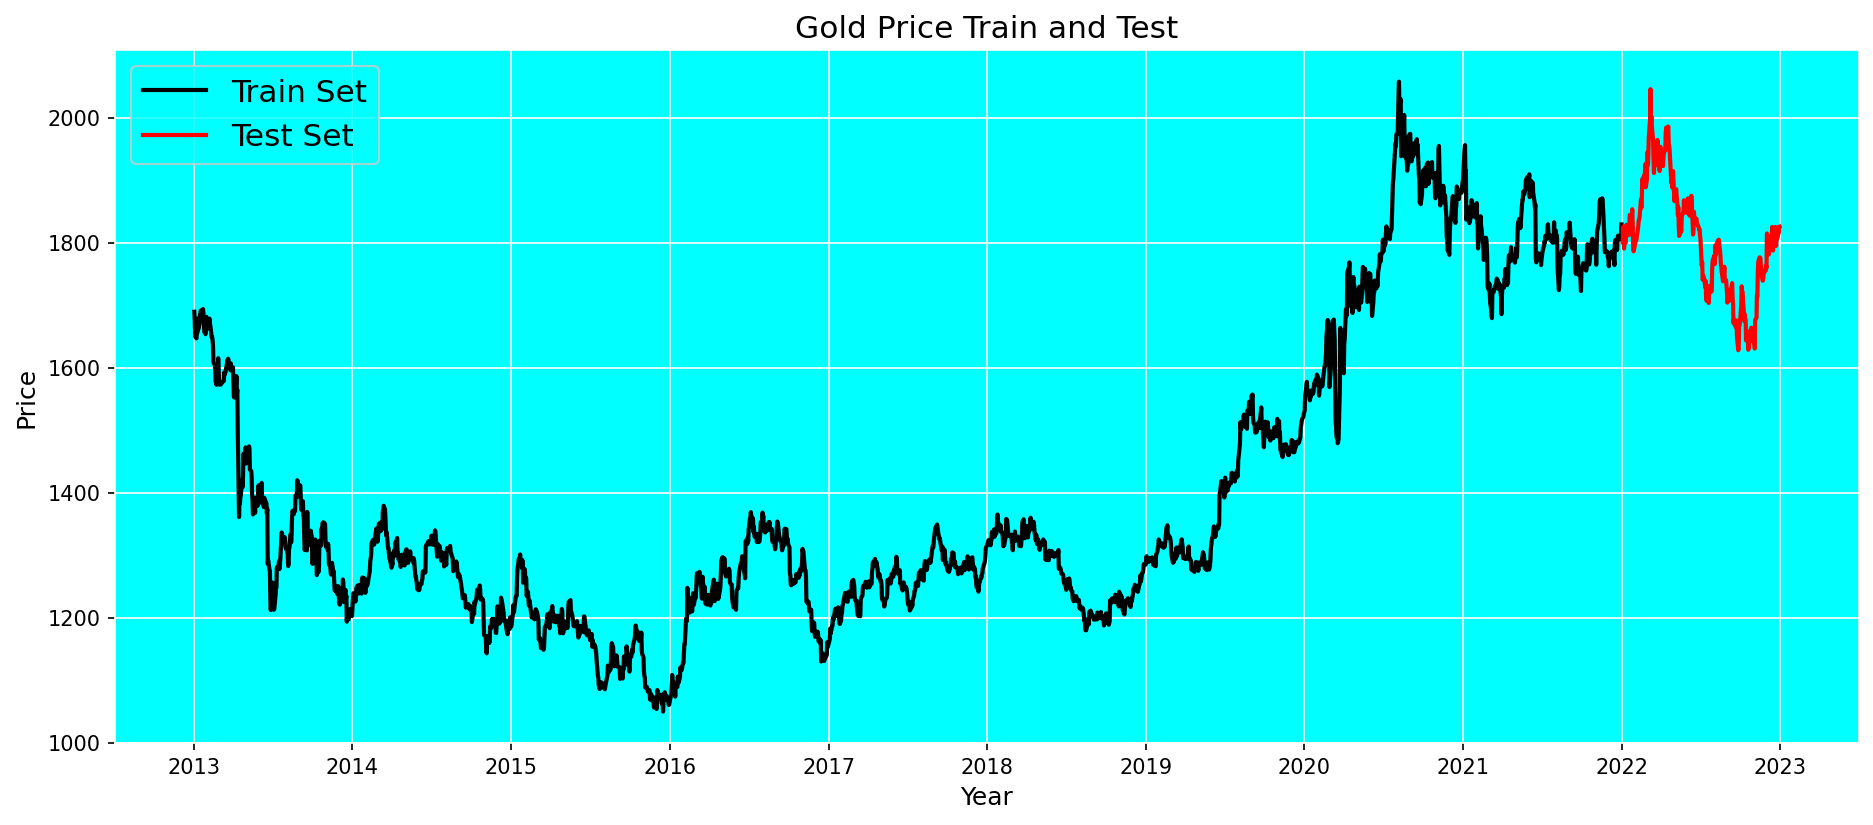

X_train shape: (2263, 60, 1)
Y_train shape: (2263, 1)
X_test shape: (260, 60, 1)
Y_test shape: (260, 1)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 60, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 60, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 60, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 85,057 (332.25 KB)

 Trainable params: 85,057 (332.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
151/151 ━━━━━━━━━━━━━━━━━━━━ 19s 88ms/step - loss: 0.0134 - val_loss: 0.0999
Epoch 2/150
151/151 ━━━━━━━━━━━━━━━━━━━━ 20s 86ms/step - loss: 0.0014 - val_loss: 0.0783
Epoch 3/150
151/151 ━━━━━━━━━━━━━━━━━━━━ 16s 104ms/step - loss: 0.0011 - val_loss: 0.0693
Epoch 4/150
151/151 ━━━━━━━━━━━━━━━━━━━━ 18s 89ms/step - loss: 8.4946e-04 - val_loss: 0.0628
Epoch 5/150
151/151 ━━━━━━━━━━━━━━━━━━━━ 16s 105ms/step - loss: 9.4495e-04 - val_loss: 0.0602
Epoch 6/150
151/151 ━━━━━━━━━━━━━━━━━━━━ 19s 93ms/step - loss: 7.0960e-04 - val_loss: 0.0548
Epoch 7/150
151/151 ━━━━━━━━━━━━━━━━━━━━ 13s 86ms/step - loss: 6.3028e-04 - val_loss: 0.0513
Epoch 8/150
151/151 ━━━━━━━━━━━━━━━━━━━━ 14s 90ms/step - loss: 5.8569e-04 - val_loss: 0.0481
Epoch 9/150
151/151 ━━━━━━━━━━━━━━━━━━━━ 20s 87ms/step - loss: 4.7476e-04 - val_loss: 0.0450
Epoch 10/150
151/151 ━━━━━━━━━━━━━━━━━━━━ 13s 87ms/step - loss: 4.0123e-04 - val_loss: 0.0429
Epoch 11/150
151/151 ━━━━━━━━━━━━━━━━━━━━ 12s 82ms/step - loss: 4.6211e-04 - va

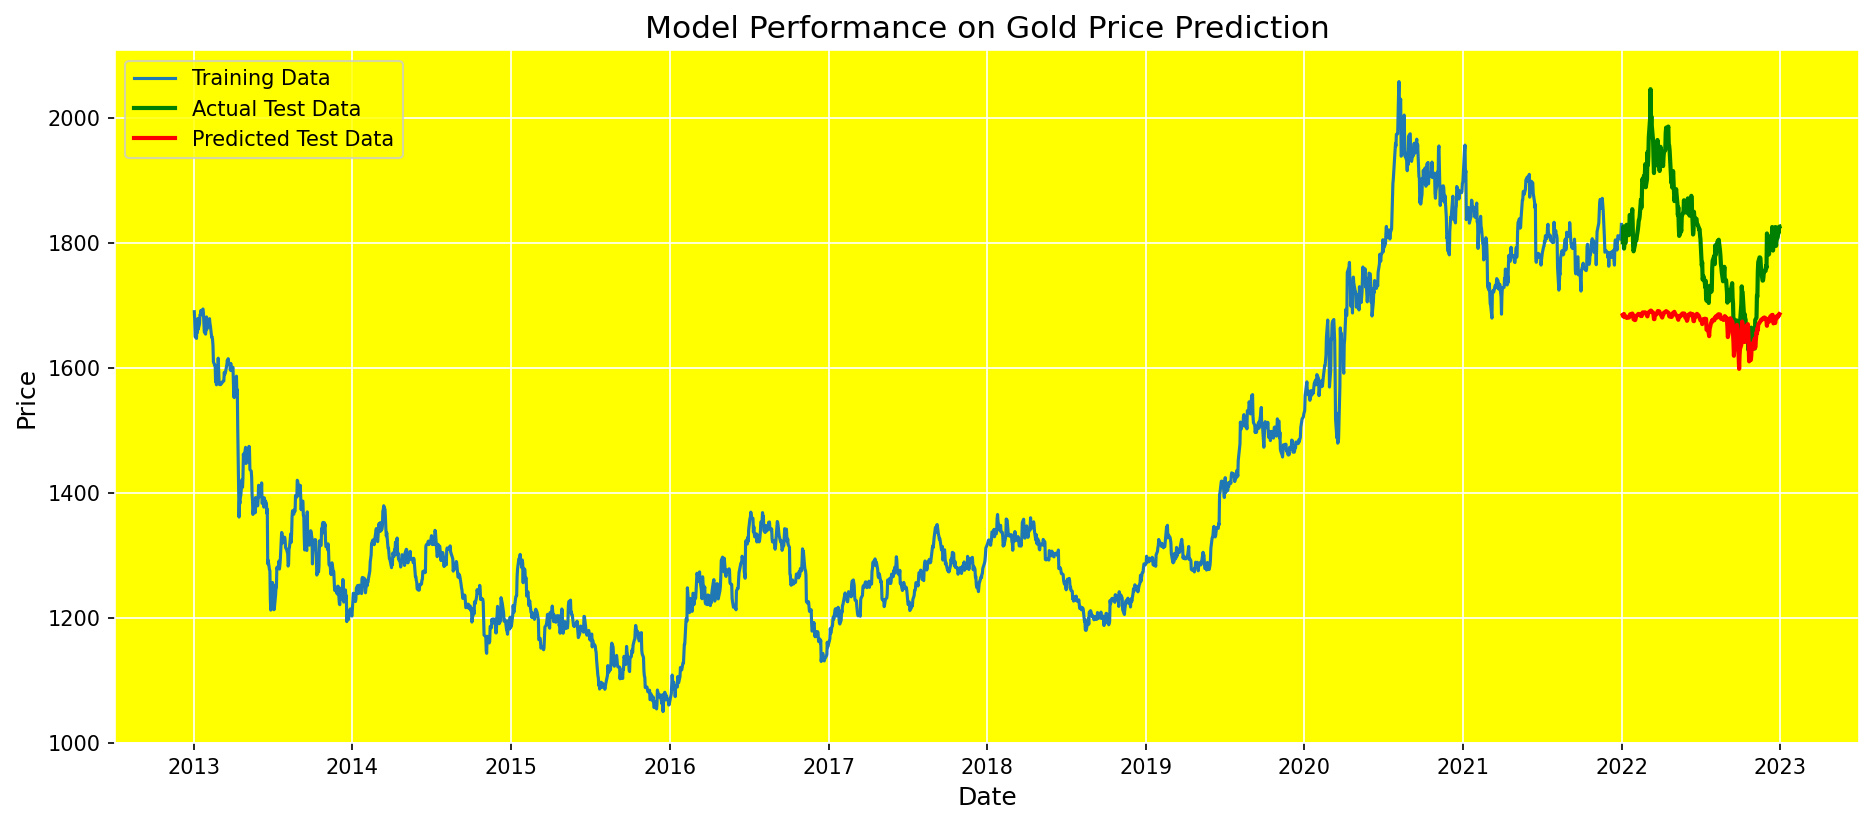

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_percentage_error
import tensorflow as tf
from keras import Model
from keras.layers import LSTM, Dropout, Dense, Input

# Load dataset
df = pd.read_csv('Gold Price (2013-2023).csv')
df.info()

# Data Preprocessing
df.drop(["Vol.","Change %"], axis=1, inplace=True)
df['Date'] = pd.to_datetime(df['Date'])
df.sort_values(by='Date', ascending=True, inplace=True)
df.reset_index(drop=True, inplace=True)

NumCols = df.columns.drop(['Date'])
df[NumCols] = df[NumCols].replace({',':''}, regex=True)
df[NumCols] = df[NumCols].astype('float64')

print(df.head())
print("Duplicated rows:", df.duplicated().sum())
print("Null values:\n", df.isnull().sum())

# Visualization of Full Data
fig = px.line(y=df.Price, x=df.Date)
fig.update_traces(line_color="black")
fig.update_layout(
    xaxis_title="Date",
    yaxis_title="Price",
    title={'text':'Gold Price Data','y':0.95,'x':0.5,'xanchor':'center'},
    plot_bgcolor='rgba(255,223,0,0.9)'
)
fig.show()

# Train Test Split - Test set: Year 2022
test_size = df[df.Date.dt.year == 2022].shape[0]
print("Test data count:", test_size)

# Plot Train vs Test
plt.figure(figsize=(15,6), dpi=150)
plt.rcParams['axes.facecolor'] = 'cyan'
plt.rc('axes', edgecolor='white')
plt.plot(df.Date[:-test_size], df.Price[:-test_size], color='black', lw=2)
plt.plot(df.Date[-test_size:], df.Price[-test_size:], color='red', lw=2)
plt.title('Gold Price Train and Test', fontsize=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Price', fontsize=12)
plt.legend(['Train Set','Test Set'], loc="upper left", prop={'size':15})
plt.grid(color='white')
plt.show()

# Scaling Data
scaler = MinMaxScaler()
scaler.fit(df.Price.values.reshape(-1,1))

window_size = 60

# Training Data Preparation
train_data = df.Price[:-test_size]
train_data = scaler.transform(train_data.values.reshape(-1,1))

X_train = []
Y_train = []
for i in range(window_size, len(train_data)):
    X_train.append(train_data[i-window_size:i, 0])
    Y_train.append(train_data[i, 0])

# Testing Data Preparation
test_data = df.Price[-test_size-window_size:]
test_data = scaler.transform(test_data.values.reshape(-1,1))

X_test = []
Y_test = []
for i in range(window_size, len(test_data)):
    X_test.append(test_data[i-window_size:i, 0])
    Y_test.append(test_data[i, 0])

# Convert to numpy arrays
X_train = np.array(X_train)
Y_train = np.array(Y_train)
X_test = np.array(X_test)
Y_test = np.array(Y_test)

# Reshape to LSTM input format
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))
Y_train = Y_train.reshape(-1,1)
Y_test = Y_test.reshape(-1,1)

print("X_train shape:", X_train.shape)
print("Y_train shape:", Y_train.shape)
print("X_test shape:", X_test.shape)
print("Y_test shape:", Y_test.shape)

# Define LSTM Model
def define_model():
    input1 = Input(shape=(window_size, 1))
    x = LSTM(units=64, return_sequences=True)(input1)
    x = Dropout(0.2)(x)
    x = LSTM(units=64, return_sequences=True)(x)
    x = Dropout(0.2)(x)
    x = LSTM(units=64)(x)
    x = Dense(32, activation='softmax')(x)
    dnn_output = Dense(1)(x)

    model = Model(inputs=input1, outputs=[dnn_output])
    model.compile(loss='mean_squared_error', optimizer='Nadam')
    model.summary()
    return model

model = define_model()

# Train Model
history = model.fit(X_train, Y_train, epochs=150, batch_size=12, validation_split=0.2)

# Model Performance
result = model.evaluate(X_test, Y_test)
y_pred = model.predict(X_test)

MAPE = mean_absolute_percentage_error(Y_test, y_pred)
accuracy = 1 - MAPE

print("Test Loss:", result)
print("Test MAPE:", MAPE)
print("Test Accuracy:", accuracy)

# Inverse Transform Predictions
y_test_true = scaler.inverse_transform(Y_test)
y_test_pred = scaler.inverse_transform(y_pred)

# Final Prediction Plot
plt.figure(figsize=(15,6), dpi=150)
plt.rcParams['axes.facecolor'] = 'yellow'
plt.rc('axes', edgecolor='white')
plt.plot(df['Date'].iloc[:-test_size], scaler.inverse_transform(train_data))
plt.plot(df['Date'].iloc[-test_size:], y_test_true, color='green', lw=2)
plt.plot(df['Date'].iloc[-test_size:], y_test_pred, color='red', lw=2)
plt.title("Model Performance on Gold Price Prediction", fontsize=15)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price', fontsize=12)
plt.legend(['Training Data', 'Actual Test Data', 'Predicted Test Data'], loc='upper left')
plt.grid(color='white')
plt.show()
